# IAU Project

## Faza 2 - Predspracovanie dát

### Andrii Novitskyi - 50%
### Andriy Kardash - 50%

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import (StratifiedKFold, train_test_split)
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler, PowerTransformer, OneHotEncoder
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, RobustScaler,
    PowerTransformer, QuantileTransformer, FunctionTransformer,
    OneHotEncoder,
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif


In [2]:

data_path = Path("Datasets/037")

files = [
    file
    for file in data_path.rglob("*")
    if file.is_file()
]


for file in files:
    print(file)

gateways = pd.read_csv(data_path / "gateways.csv",sep=';')
readings = pd.read_csv(data_path / "readings.csv",sep='\t')
units = pd.read_csv(data_path / "units.csv",sep=',')

Datasets\037\gateways.csv
Datasets\037\readings.csv
Datasets\037\units.csv


### Vstupné súbory používajú rozdielne oddeľovacie znaky. Z tohto dôvodu bol
### oddeľovač pre každý dataset zadaný explicitne

In [3]:
datasets = {
    "Gateways": gateways,
    "Readings": readings,
    "Units": units
}

for name, dataset in datasets.items():
    print(f"{name}: {dataset.shape}")
    print(dataset.columns.tolist())
    print()



display(gateways.head())
display(readings.head())
display(units.head())

Gateways: (16000, 14)
['vendor', 'gatewayId', 'lat', 'seen_last', 'ipv4', 'versionFirmware', 'Technician', 'id_unit', 'modelHardware', 'id_depot', 'macAddress', 'Lon', 'dbm_signal', 'date_install']

Readings: (12618, 14)
['id_unit', 'ts_cycle', 'motorCurrent', 'filter_dp', 'oilTemperature', 'pressure_reservoir', 'pressure_working', 'pressureOil', 'vibrationRms', 'flowmeter', 'intake_humidity', 'ambientNoise', 'bearingTemp', 'failure']

Units: (2000, 7)
['Manufacturer', 'class_duty', 'id_unit', 'lastOverhaul', 'lineCode', 'id_depot', 'hoursService']



,vendor,gatewayId,lat,seen_last,ipv4,versionFirmware,Technician,id_unit,modelHardware,id_depot,macAddress,Lon,dbm_signal,date_install
0,"Holland, Moore and Foster",GW-00000,39.85515,25 Jan 2025,201.144.200.206,v3.4.1,Viviane Jopich,70.0,GWX-300,5,4b:57:9d:d8:85:7e,-8.87854,-67.0,2023-05-10
1,Castro Nascimento Lda.,GW-00001,39.97771,24 May 2024,162.167.208.12,v2.7.0,Klaus Peter Klemt-Klapp,463.0,GWX-200,67,28:1b:c1:bf:d2:72,-9.09701,-78.4,"04/18/2021, 00:00:00"
2,Green-Mitchell,GW-00002,39.68046,2024/10/21,214.16.189.57,v1.2.5,Steven Luna,759.0,NODE-9,109,2c:75:86:3d:87:96,-8.56949,-73.9,2021-10-22
3,Stey Fechner GbR,GW-00003,40.37614,09 Jul 2024,250.7.67.70,v3.4.1,Adriana Pinho,1966.0,GWX-100,31,50:33:0f:fe:aa:b6,-9.20827,-84.9,25 Apr 2021
4,Misicher Nette GmbH & Co. KGaA,GW-00004,40.07243,"10/24/2024, 00:00:00",225.244.98.178,v3.4.1,Mark Hines,457.0,NODE-7,34,01:f9:49:1a:95:c1,-6.35564,-71.6,2015/04/14


,id_unit,ts_cycle,motorCurrent,filter_dp,oilTemperature,pressure_reservoir,pressure_working,pressureOil,vibrationRms,flowmeter,intake_humidity,ambientNoise,bearingTemp,failure
0,U01130,"02/10/2023, 17:12:00",4.36969,28.64924,49.67845,7.34282,7.31041,2.31187,4.99789,30.25891,66.67165,72.94257,64.95347,0
1,U00848,18 Sep 2023,4.22091,23.03530,41.77282,8.50849,8.53387,3.60240,1.87873,30.49048,89.24165,85.55312,74.46724,0
2,U00943,2023/12/29,2.80830,44.64527,69.78227,9.84619,9.70007,4.82881,4.49602,31.08300,80.81591,74.80889,60.05191,0
3,U01894,"11/12/2023, 15:24:00",4.45080,23.51547,47.49275,10.08831,10.00805,4.95817,2.15054,24.19140,17.74420,78.35942,67.82175,0
4,U00083,18 Nov 2023,3.97643,17.19827,70.25846,7.86674,7.88600,2.37735,4.11747,26.91899,19.60671,66.19757,59.54418,0


,Manufacturer,class_duty,id_unit,lastOverhaul,lineCode,id_depot,hoursService
0,Jäkel,L,1,05 Dec 2019,L6,12,13856.6
1,"Clark, Jackson and Anderson",H,2,"03/19/2023, 00:00:00",L4,109,14557.4
2,Pinto,1,3,2020-09-28,L6,26,15652.8
3,Fleming Group,N,4,2023/11/30,L6,68,NaN
4,Pinto,heavy,5,26 Feb 2018,L3,102,6141.3


In [4]:
print("Gateways columns:")
print(gateways.columns.tolist())

print("\nReadings columns:")
print(readings.columns.tolist())

print("\nUnits columns:")
print(units.columns.tolist())

Gateways columns:
['vendor', 'gatewayId', 'lat', 'seen_last', 'ipv4', 'versionFirmware', 'Technician', 'id_unit', 'modelHardware', 'id_depot', 'macAddress', 'Lon', 'dbm_signal', 'date_install']

Readings columns:
['id_unit', 'ts_cycle', 'motorCurrent', 'filter_dp', 'oilTemperature', 'pressure_reservoir', 'pressure_working', 'pressureOil', 'vibrationRms', 'flowmeter', 'intake_humidity', 'ambientNoise', 'bearingTemp', 'failure']

Units columns:
['Manufacturer', 'class_duty', 'id_unit', 'lastOverhaul', 'lineCode', 'id_depot', 'hoursService']


### since variable atribut failure is in the reading then reading is the base dataset, one measurement cycle of one unit at a particular ts_cycle

In [5]:
print(
    "Gateways and Readings:",
    set(gateways.columns) & set(readings.columns)
)

print(
    "Gateways and Units:",
    set(gateways.columns) & set(units.columns)
)

print(
    "Readings and Units:",
    set(readings.columns) & set(units.columns)
)

Gateways and Readings: {'id_unit'}
Gateways and Units: {'id_unit', 'id_depot'}
Readings and Units: {'id_unit'}


In [6]:
print("reading rows:", len(readings))

print(
    "Unique id_unit + ts_cycle:",
    readings[["id_unit", "ts_cycle"]]
    .drop_duplicates()
    .shape[0]
)

print(
    "Duplicated id_unit + ts_cycle:",
    readings.duplicated(
        subset=["id_unit", "ts_cycle"]
    ).sum()
)

reading rows: 12618
Unique id_unit + ts_cycle: 12413
Duplicated id_unit + ts_cycle: 205


### After observation, it was found out that one unit of measurements in reading is represented with a a unique combination of id_unit and ts_cycle. Rows where combination is not unique (205 rows)

In [7]:
print(
    "Completely duplicated rows:",
    readings.duplicated().sum()
)

Completely duplicated rows: 186


### 186 rows are complete duplicatedswhich represent the same measurement and 205 - 189 = 19 rows differ in at least one value.

In [8]:
readings_without_duplicates = readings.drop_duplicates()

conflicting_cycles = readings_without_duplicates[
    readings_without_duplicates.duplicated(
        subset=["id_unit", "ts_cycle"],
        keep=False
    )
].sort_values(["id_unit", "ts_cycle"])

print(
    "Rows involved in conflicting cycles:",
    len(conflicting_cycles)
)

print(
    "Number of conflicting cycle groups:",
    conflicting_cycles.groupby(
        ["id_unit", "ts_cycle"]
    ).ngroups
)

display(conflicting_cycles)

Rows involved in conflicting cycles: 38
Number of conflicting cycle groups: 19


,id_unit,ts_cycle,motorCurrent,filter_dp,oilTemperature,pressure_reservoir,pressure_working,pressureOil,vibrationRms,flowmeter,intake_humidity,ambientNoise,bearingTemp,failure
2005,U00032,2023/10/12,4.35240,17.15376,45.35273,9.00545,8.89095,4.00633,6.54306,26.95236,79.81643,76.65725,75.41390,0
7681,U00032,2023/10/12,7.12740,15.12888,58.18034,8.97236,8.53935,4.26794,2.56571,23.35472,38.55386,67.42724,77.03787,0
2318,U00071,2023-10-07,8.28045,23.67242,63.31915,8.01949,8.27628,2.92703,2.31301,30.03363,59.87044,75.33242,68.78547,0
2905,U00071,2023-10-07,8.08684,16.92073,48.17299,8.53107,8.68286,3.49151,6.50042,30.06184,26.13176,72.54233,54.84770,0
3039,U00130,2023/01/05,5.99018,13.95925,57.64779,8.10456,8.26077,3.16462,5.01357,27.22841,30.01438,73.24225,62.83620,0
5424,U00130,2023/01/05,5.56193,20.75549,56.08689,9.57682,9.74196,4.50544,4.15699,23.99710,56.90525,75.14271,64.50457,0
8643,U00131,2023-08-21,6.26486,27.40713,38.63368,9.58495,9.39346,4.56932,1.99188,19.52254,73.32488,76.94241,77.65421,0
9172,U00131,2023-08-21,4.78847,24.34563,67.91887,8.46736,8.62370,3.57375,1.79134,29.24994,89.25581,70.56869,50.19603,0
5317,U00138,2023/05/19,5.60416,17.83368,51.86838,9.56384,9.68258,4.67103,4.61489,27.58880,10.61184,74.46813,67.06151,0
5679,U00138,2023/05/19,4.34585,31.33845,60.86035,8.41328,8.29496,3.90827,3.54085,32.16959,35.58525,77.72031,68.02897,0


In [9]:
# Gateways

gateways['seen_last'] = pd.to_datetime(gateways['seen_last'], format="mixed", errors="coerce")
gateways['date_install'] = pd.to_datetime(gateways['date_install'], format="mixed", errors="coerce")
gateways.loc[gateways["seen_last"] < gateways["date_install"], 'seen_last'] = pd.NaT
gateways["id_unit"] = gateways["id_unit"].astype("Int64")

# Readings

readings["id_unit"] = readings["id_unit"].str.extract(r"(\d+)")[0].astype(int)
readings["ts_cycle"] = pd.to_datetime(readings["ts_cycle"], format="mixed")
readings.loc[readings['motorCurrent'] == 99, 'motorCurrent'] = np.nan
readings.loc[readings['oilTemperature'] == -999, 'oilTemperature'] = np.nan
readings = readings.drop_duplicates().reset_index(drop=True)
for c in ["filter_dp", "vibrationRms"]:
    readings[f"{c}_missing"] = readings[c].isna().astype(int)


# Units
units['lastOverhaul'] = pd.to_datetime(units['lastOverhaul'], format="mixed", errors="coerce")
DUTY_MAP = {
    "l": 1, "light": 1, "1": 1,
    "n": 2, "normal": 2, "med": 2, "2": 2,
    "h": 3, "heavy": 3, "3": 3,
}

duty_clean = units["class_duty"].astype("string").str.strip().str.lower()
units["class_duty"] = duty_clean.map(DUTY_MAP).astype("Int64")

### most of the measurements have the same failure value, and only in one combination of id_unit + ts_cycle this value differs. Complete duplicates will be removed, but since ts_cycle represent only the data, non-identical rows will remain. (supposing the same measurement was took more than one time on the same day)

In [10]:
print("Number of rows in units:", len(units))
print("Number of unique id_unit values:", units["id_unit"].nunique())
print(
    "Number of duplicated id_unit values:",
    units["id_unit"].duplicated().sum()
)
print(
    "Number of missing id_unit values:",
    units["id_unit"].isna().sum()
)

Number of rows in units: 2000
Number of unique id_unit values: 2000
Number of duplicated id_unit values: 0
Number of missing id_unit values: 0


In [11]:
units.head()

,Manufacturer,class_duty,id_unit,lastOverhaul,lineCode,id_depot,hoursService
0,Jäkel,1,1,2019-12-05,L6,12,13856.6
1,"Clark, Jackson and Anderson",3,2,2023-03-19,L4,109,14557.4
2,Pinto,1,3,2020-09-28,L6,26,15652.8
3,Fleming Group,2,4,2023-11-30,L6,68,NaN
4,Pinto,3,5,2018-02-26,L3,102,6141.3


In [12]:
readings.head()

,id_unit,ts_cycle,motorCurrent,filter_dp,oilTemperature,pressure_reservoir,pressure_working,pressureOil,vibrationRms,flowmeter,intake_humidity,ambientNoise,bearingTemp,failure,filter_dp_missing,vibrationRms_missing
0,1130,2023-02-10 17:12:00,4.36969,28.64924,49.67845,7.34282,7.31041,2.31187,4.99789,30.25891,66.67165,72.94257,64.95347,0,0,0
1,848,2023-09-18 00:00:00,4.22091,23.03530,41.77282,8.50849,8.53387,3.60240,1.87873,30.49048,89.24165,85.55312,74.46724,0,0,0
2,943,2023-12-29 00:00:00,2.80830,44.64527,69.78227,9.84619,9.70007,4.82881,4.49602,31.08300,80.81591,74.80889,60.05191,0,0,0
3,1894,2023-11-12 15:24:00,4.45080,23.51547,47.49275,10.08831,10.00805,4.95817,2.15054,24.19140,17.74420,78.35942,67.82175,0,0,0
4,83,2023-11-18 00:00:00,3.97643,17.19827,70.25846,7.86674,7.88600,2.37735,4.11747,26.91899,19.60671,66.19757,59.54418,0,0,0


### id-unit formats differe so they need to be change dinto the same format

In [13]:
units["id_unit_key"] = pd.to_numeric(
    units["id_unit"],
    errors="coerce"
).astype("Int64")

In [14]:
readings["id_unit_key"] = pd.to_numeric(
    readings["id_unit"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.removeprefix("U"),
    errors="coerce"
).astype("Int64")

In [15]:
display(
    units[
        ["id_unit", "id_unit_key"]
    ].head(10)
)

display(
    readings[
        ["id_unit", "id_unit_key"]
    ].head(10)
)

,id_unit,id_unit_key
0,1,1
1,2,2
2,3,3
3,4,4
4,5,5
5,6,6
6,7,7
7,8,8
8,9,9
9,10,10


,id_unit,id_unit_key
0,1130,1130
1,848,848
2,943,943
3,1894,1894
4,83,83
5,777,777
6,688,688
7,1370,1370
8,247,247
9,946,946


### in both datasets id_unit were assigned type int

In [16]:
print("Number of rows in units:", len(units))
print(
    "Unique normalized units:",
    units["id_unit_key"].nunique()
)
print(
    "Duplicated normalized units:",
    units["id_unit_key"].duplicated().sum()
)
print(
    "Missing normalized units:",
    units["id_unit_key"].isna().sum()
)

Number of rows in units: 2000
Unique normalized units: 2000
Duplicated normalized units: 0
Missing normalized units: 0


In [17]:
reading_unit_ids = set(readings["id_unit_key"])
unit_ids = set(units["id_unit_key"])

missing_in_units = reading_unit_ids - unit_ids

print(
    "Reading units not found in units:",
    len(missing_in_units)
)

print(sorted(missing_in_units)[:20])

Reading units not found in units: 111
[np.int64(90001), np.int64(90002), np.int64(90005), np.int64(90010), np.int64(90030), np.int64(90035), np.int64(90054), np.int64(90077), np.int64(90081), np.int64(90083), np.int64(90092), np.int64(90093), np.int64(90099), np.int64(90101), np.int64(90102), np.int64(90112), np.int64(90119), np.int64(90120), np.int64(90125), np.int64(90126)]


### 111 valus for id-unit in reading do not have corresponding row in units dataset

In [18]:
missing_unit_mask = readings["id_unit_key"].isin(missing_in_units)

print(
    "Unique missing units:",
    readings.loc[missing_unit_mask, "id_unit_key"].nunique()
)

print(
    "Reading rows with no matching unit:",
    missing_unit_mask.sum()
)



Unique missing units: 111
Reading rows with no matching unit: 121


### since id_unit in reading can be shared among other measurement, despite of 111 unique value which are not included in units, there are also duplicated of these rows which makes the number of rows without a data assigned from unit - 122

In [19]:
display(
    readings.loc[missing_unit_mask]
    .sort_values(["id_unit_key", "ts_cycle"])
    .head(30)
)

,id_unit,ts_cycle,motorCurrent,filter_dp,oilTemperature,pressure_reservoir,pressure_working,pressureOil,vibrationRms,flowmeter,intake_humidity,ambientNoise,bearingTemp,failure,filter_dp_missing,vibrationRms_missing,id_unit_key
9463,90001,2023-01-08 00:00:00,4.61808,16.91618,61.64541,8.99371,8.94367,3.47438,8.47014,32.96959,51.79001,89.53124,57.81237,0,0,0,90001
3460,90001,2023-12-23 00:00:00,9.23093,29.23132,52.29549,9.63200,9.64805,4.26823,0.85261,33.13956,46.48159,86.04681,71.06732,0,0,0,90001
3373,90002,2023-02-12 00:00:00,2.97062,9.79832,44.89764,8.39591,8.54568,3.13107,1.94272,26.57043,47.27167,65.55677,81.45000,0,0,0,90002
6165,90002,2023-11-14 00:00:00,3.24440,20.26538,52.76692,8.74667,8.89841,3.67865,2.52919,29.12073,27.69169,70.42998,66.86160,0,0,0,90002
6448,90005,2023-09-19 00:00:00,7.54856,21.28621,44.10811,8.26120,8.24875,3.19977,2.04213,22.70890,85.49729,68.74093,57.81270,0,0,0,90005
10751,90010,2023-07-24 00:00:00,4.20566,27.00763,51.15061,8.34128,8.52876,3.46635,3.24375,23.98106,23.36035,74.78219,71.28933,0,0,0,90010
5081,90030,2023-12-14 01:30:00,5.55186,28.69114,48.52296,9.36780,9.30803,4.31523,3.61312,26.94594,67.86193,78.09257,71.34777,0,0,0,90030
3109,90035,2023-05-02 00:00:00,4.44077,12.38933,51.01765,9.01408,9.05445,4.36976,4.00167,30.29333,64.42437,75.47371,58.53679,0,0,0,90035
6229,90054,2023-12-22 00:00:00,6.59299,29.62719,60.40211,8.65615,8.73558,4.12839,3.97299,35.22304,63.00646,76.60263,68.11696,0,0,0,90054
11858,90077,2023-09-03 00:00:00,2.90312,21.11323,45.49549,8.56610,8.60802,3.22805,1.25545,30.52726,32.26283,71.76824,74.58435,0,0,0,90077


In [20]:
print(
    "1 exists:",
    (readings["id_unit_key"] == 1).any()
)

print(
    "90001 exists:",
    (readings["id_unit_key"] == 90001).any()
)

1 exists: True
90001 exists: True


### all values without a corresponding data from units start with 9 so we checked whether U90001 can be relate to 1. As a cocnlusion they are not relate isnce there are both values in a dataset

In [21]:
readings_clean = readings.drop_duplicates().copy()

data = readings_clean.merge(
    units.drop(columns="id_unit"),
    on="id_unit_key",
    how="left",
    validate="many_to_one",
)

In [22]:
print("Readings before merge:", len(readings_clean))
print("Rows after merge:", len(data))

Readings before merge: 12432
Rows after merge: 12432


In [23]:
data.head(10)

,id_unit,ts_cycle,motorCurrent,filter_dp,oilTemperature,pressure_reservoir,pressure_working,pressureOil,vibrationRms,flowmeter,...,failure,filter_dp_missing,vibrationRms_missing,id_unit_key,Manufacturer,class_duty,lastOverhaul,lineCode,id_depot,hoursService
0,1130,2023-02-10 17:12:00,4.36969,28.64924,49.67845,7.34282,7.31041,2.31187,4.99789,30.25891,...,0,0,0,1130,Barth Gute OHG mbH,2,2020-02-17,L5,40.0,6665.4
1,848,2023-09-18 00:00:00,4.22091,23.03530,41.77282,8.50849,8.53387,3.60240,1.87873,30.49048,...,0,0,0,848,Higgins Inc,1,2022-06-03,L3,27.0,NaN
2,943,2023-12-29 00:00:00,2.80830,44.64527,69.78227,9.84619,9.70007,4.82881,4.49602,31.08300,...,0,0,0,943,Nette Weller Stiftung & Co. KGaA,1,2019-10-14,L6,14.0,16720.9
3,1894,2023-11-12 15:24:00,4.45080,23.51547,47.49275,10.08831,10.00805,4.95817,2.15054,24.19140,...,0,0,0,1894,Striebitz AG,2,2019-02-02,L2,69.0,12480.2
4,83,2023-11-18 00:00:00,3.97643,17.19827,70.25846,7.86674,7.88600,2.37735,4.11747,26.91899,...,0,0,0,83,Hunt LLC,2,2017-10-09,L3,48.0,9389.6
5,777,2023-07-06 00:00:00,3.22686,28.24065,60.57740,9.00718,9.20808,4.48304,3.30593,32.48052,...,0,0,0,777,Castro Nascimento Lda.,1,2022-11-24,L3,39.0,8219.0
6,688,2023-09-09 00:00:00,2.76081,15.84201,60.89518,9.15108,9.37328,3.61046,2.11979,25.28018,...,0,0,0,688,Pinto,1,2019-08-10,L6,1.0,10525.3
7,1370,2023-09-20 00:00:00,4.50663,19.46103,42.76148,8.03207,8.31141,3.43468,1.54556,21.92854,...,0,0,0,1370,Moreira Henriques S.A.,1,2023-09-29,L6,111.0,16085.6
8,247,2023-09-25 00:00:00,4.64585,41.59096,71.94085,8.59036,8.89304,3.66107,1.82557,30.47198,...,0,0,0,247,Börner Klemt KG,2,2016-12-21,L5,18.0,12930.7
9,946,2023-12-14 00:00:00,9.18168,37.39852,52.08046,8.02453,8.24464,2.78188,5.34202,33.58937,...,0,0,0,946,Salazar-Harris,3,2021-06-15,L3,119.0,9942.1


In [24]:
display(
    data[data["Manufacturer"].isna()]
)

,id_unit,ts_cycle,motorCurrent,filter_dp,oilTemperature,pressure_reservoir,pressure_working,pressureOil,vibrationRms,flowmeter,...,failure,filter_dp_missing,vibrationRms_missing,id_unit_key,Manufacturer,class_duty,lastOverhaul,lineCode,id_depot,hoursService
113,90081,2023-11-09 00:00:00,8.09272,24.24770,60.49406,8.47530,8.54376,3.12272,1.17610,22.35824,...,0,0,0,90081,NaN,<NA>,NaT,NaN,NaN,NaN
130,90396,2023-04-03 00:00:00,4.87806,38.56177,79.16946,8.79828,8.50186,3.68216,1.52900,33.10192,...,0,0,0,90396,NaN,<NA>,NaT,NaN,NaN,NaN
264,90357,2023-03-07 05:01:00,9.03454,26.26709,53.02407,8.70299,8.66560,3.86911,1.26883,21.94601,...,0,0,0,90357,NaN,<NA>,NaT,NaN,NaN,NaN
293,90323,2023-09-10 00:00:00,7.87523,26.32598,15.00000,8.87393,8.78140,3.68672,1.75551,29.95337,...,0,0,0,90323,NaN,<NA>,NaT,NaN,NaN,NaN
385,90270,2023-01-11 00:00:00,4.67702,26.61143,36.07523,8.61352,8.59516,3.78436,1.02511,26.62764,...,0,0,0,90270,NaN,<NA>,NaT,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12126,90391,2023-10-08 00:00:00,6.98345,14.84817,23.02443,8.73671,8.67595,3.31412,2.34774,28.75813,...,0,0,0,90391,NaN,<NA>,NaT,NaN,NaN,NaN
12144,90235,2023-07-19 00:00:00,3.16738,23.03618,52.21291,8.39977,8.55105,4.10023,2.26784,35.33094,...,0,0,0,90235,NaN,<NA>,NaT,NaN,NaN,NaN
12247,90210,2023-07-01 04:42:00,4.90359,10.49898,57.99938,9.44626,9.35361,3.28957,1.63341,30.71579,...,0,0,0,90210,NaN,<NA>,NaT,NaN,NaN,NaN
12255,90396,2023-04-04 00:00:00,4.47671,19.62528,77.34806,8.02995,8.09985,2.97059,3.37861,34.76185,...,0,0,0,90396,NaN,<NA>,NaT,NaN,NaN,NaN


### we performed left merge to avoid getting rid of measurements which do not have metadata from units

In [25]:
metadata_missing = data["Manufacturer"].isna()

print(
    "Rows without unit metadata:",
    metadata_missing.sum()
)

print(
    "Unique units without metadata:",
    data.loc[
        metadata_missing,
        "id_unit_key"
    ].nunique()
)

Rows without unit metadata: 121
Unique units without metadata: 111


In [26]:
print("id_unit type:", gateways["id_unit"].dtype)
print("gatewayId type:", gateways["gatewayId"].dtype)

print("\nid_unit examples:")
print(gateways["id_unit"].head(10).tolist())

print("\ngatewayId examples:")
print(gateways["gatewayId"].head(10).tolist())

id_unit type: Int64
gatewayId type: str

id_unit examples:
[70, 463, 759, 1966, 457, 1898, 333, 360, 320, 813]

gatewayId examples:
['GW-00000', 'GW-00001', 'GW-00002', 'GW-00003', 'GW-00004', 'GW-00005', 'GW-00006', 'GW-00007', 'GW-00008', 'GW-00009']


### possible shared value is id_unit so we cahnge it into int

In [27]:
gateways["id_unit_key"] = pd.to_numeric(
    gateways["id_unit"],
    errors="coerce"
).astype("Int64")


display(
    gateways[
        ["id_unit", "id_unit_key"]
    ].head(10)
)

print(
    "Missing original id_unit:",
    gateways["id_unit"].isna().sum()
)

print(
    "Missing normalized id_unit:",
    gateways["id_unit_key"].isna().sum()
)

,id_unit,id_unit_key
0,70,70
1,463,463
2,759,759
3,1966,1966
4,457,457
5,1898,1898
6,333,333
7,360,360
8,320,320
9,813,813


Missing original id_unit: 14000
Missing normalized id_unit: 14000


In [28]:
gateways_with_unit = gateways.dropna(
    subset=["id_unit_key"]
).copy()

print(
    "Gateway rows with unit:",
    len(gateways_with_unit)
)

print(
    "Unique units:",
    gateways_with_unit["id_unit_key"].nunique()
)

print(
    "Duplicated units:",
    gateways_with_unit["id_unit_key"].duplicated().sum()
)

print(
    "Unique gateway IDs:",
    gateways_with_unit["gatewayId"].nunique()
)

Gateway rows with unit: 2000
Unique units: 2000
Duplicated units: 0
Unique gateway IDs: 2000


In [29]:
data_unit_ids = set(data["id_unit_key"].dropna())
gateway_unit_ids = set(
    gateways_with_unit["id_unit_key"]
)

shared_gateway_ids = data_unit_ids & gateway_unit_ids
only_in_data = data_unit_ids - gateway_unit_ids
only_in_gateways = gateway_unit_ids - data_unit_ids

print("Shared unit IDs:", len(shared_gateway_ids))
print("Units in data without gateway:", len(only_in_data))
print("Gateway units without readings:", len(only_in_gateways))

Shared unit IDs: 1998
Units in data without gateway: 111
Gateway units without readings: 2


In [30]:
print("Gateway unit IDs without readings:")
print(sorted(only_in_gateways))

Gateway unit IDs without readings:
[np.int64(1077), np.int64(1632)]


In [31]:
display(
    gateways_with_unit[
        gateways_with_unit["id_unit_key"].isin([1077, 1632])
    ]
)

,vendor,gatewayId,lat,seen_last,ipv4,versionFirmware,Technician,id_unit,modelHardware,id_depot,macAddress,Lon,dbm_signal,date_install,id_unit_key
1502,Morales Ltd,GW-01502,40.25524,2024-05-01,24.147.205.239,v3.4.1,Manuel Ferreira,1632,GWX-100,18,7a:6e:45:79:f6:a5,-7.13336,-67.8,2017-11-15,1632
1630,Maia,GW-01630,39.14850,2024-02-13,65.220.63.115,v3.4.1,Amanda Mcneil,1077,NODE-9,9,ef:52:b7:f4:ab:39,-8.44468,-72.5,2015-01-18,1077


In [32]:
display(
    readings[
        readings["id_unit_key"].isin([1077, 1632])
    ]
)

,id_unit,ts_cycle,motorCurrent,filter_dp,oilTemperature,pressure_reservoir,pressure_working,pressureOil,vibrationRms,flowmeter,intake_humidity,ambientNoise,bearingTemp,failure,filter_dp_missing,vibrationRms_missing,id_unit_key


### two measurements does not have an id which can be assigned to reading id so we dont consider them

In [33]:
gateway_columns = [
    "id_unit_key",
    "gatewayId",
    "vendor",
    "seen_last",
    "versionFirmware",
    "modelHardware",
    "dbm_signal",
    "date_install",
]

In [34]:
rows_before_gateway_merge = len(data)

data = data.merge(
    gateways_with_unit[gateway_columns],
    on="id_unit_key",
    how="left",
    validate="many_to_one",
    suffixes=("_unit", "_gateway")
)

print("Rows before merge:", rows_before_gateway_merge)
print("Rows after merge:", len(data))

Rows before merge: 12432
Rows after merge: 12432


In [35]:
print(
    "Rows without gateway metadata:",
    data["gatewayId"].isna().sum()
)

print(
    "Unique units without gateway metadata:",
    data.loc[
        data["gatewayId"].isna(),
        "id_unit_key"
    ].nunique()
)

Rows without gateway metadata: 121
Unique units without gateway metadata: 111


### Merania neznámych jednotiek
Merania jednotiek s id_unit >= 90001 (121 riadkov, ~1 % dát) nemajú záznam v *units* ani v *gateways*.
Rovnako ako vo fáze 1 ich *odstraňujeme*: imputácia by im priradila vymyslené hodnoty výrobcu, triedy zaťaženia a servisných hodín.

In [36]:
unknown_unit = data["Manufacturer"].isna()
print("Odstránené riadky (neznáma jednotka):", unknown_unit.sum())

data = data.loc[~unknown_unit].reset_index(drop=True)

print("Riadky po odstránení:", len(data))
print("Riadky bez údajov z gateways:", data["gatewayId"].isna().sum())

Odstránené riadky (neznáma jednotka): 121
Riadky po odstránení: 12311
Riadky bez údajov z gateways: 0


### Measurements from unknown units were removed because they could not be connected to the `units` or `gateways` metadata. They represented approximately 1% of the dataset, so their removal had only a small effect while avoiding observations with substantial missing metadata.

# Split data (Train/Validate)

In [37]:
X = data.drop(columns = 'failure')
y = data['failure']
groups = data["id_unit_key"]

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]


print("Train:", X_train.shape, f"({len(X_train) / len(X):.1%})")
print("Test: ", X_test.shape, f"({len(X_test) / len(X):.1%})")
print(f"Podiel failure – train: {y_train.mean():.3f}, test: {y_test.mean():.3f}")
print("Jednotky v train aj test:", len(set(X_train["id_unit_key"]) & set(X_test["id_unit_key"])))

Train: (9849, 29) (80.0%)
Test:  (2462, 29) (20.0%)
Podiel failure – train: 0.121, test: 0.121
Jednotky v train aj test: 0


# Pipe line for data trasnformation
## Type fixer class created to convert date collumns from string to pd_datetime but for machine learning dates are usless so we need to convert it to number

In [38]:

class TypeFixer(BaseEstimator, TransformerMixin):
    date_cols = ["ts_cycle", "lastOverhaul", "seen_last", "date_install"]
    drop_cols = ["id_unit", "id_unit_key", "gatewayId", "vendor", "id_depot"]

    def fit(self, X, y = None):
        self.feature_names_out_ = self._fix(X).columns.to_numpy(dtype=object)
        return self

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_out_

    def transform(self, X):
        return self._fix(X)

    def _fix(self, X):
        X = X.copy()
        for col in self.date_cols:
            X[col] = pd.to_datetime(X[col], format="mixed", errors="coerce")
        X["days_since_overhaul"] = (X["ts_cycle"] - X["lastOverhaul"]).dt.days  ### подумати як це зберігати
        X["gateway_age_days"] = (X["ts_cycle"] - X["date_install"]).dt.days ### подумати як це зберігати
        X["days_since_seen"] = (X["seen_last"] - X["ts_cycle"]).dt.days  ### подумати як це зберігати
        X["class_duty"] = X["class_duty"].astype(float)
        return X.drop(columns=self.date_cols + self.drop_cols)

### Original date columns are converted into numerical time differences. Identifiers are removed because their numerical values do not represent meaningful quantities for prediction.

In [39]:
fixed_train = TypeFixer().fit_transform(X_train)
display(fixed_train.head())
print(fixed_train.dtypes)

,motorCurrent,filter_dp,oilTemperature,pressure_reservoir,pressure_working,pressureOil,vibrationRms,flowmeter,intake_humidity,ambientNoise,...,Manufacturer,class_duty,lineCode,hoursService,versionFirmware,modelHardware,dbm_signal,days_since_overhaul,gateway_age_days,days_since_seen
0,4.36969,28.64924,49.67845,7.34282,7.31041,2.31187,4.99789,30.25891,66.67165,72.94257,...,Barth Gute OHG mbH,2.0,L5,6665.4,v3.4.1,GWX-300,-71.0,1089,-434,NaN
1,4.22091,23.03530,41.77282,8.50849,8.53387,3.60240,1.87873,30.49048,89.24165,85.55312,...,Higgins Inc,1.0,L3,NaN,v3.4.1,NODE-9,-72.0,472,2131,227.0
3,4.45080,23.51547,47.49275,10.08831,10.00805,4.95817,2.15054,24.19140,17.74420,78.35942,...,Striebitz AG,2.0,L2,12480.2,v2.7.0,NODE-9,-87.9,1744,317,228.0
4,3.97643,17.19827,70.25846,7.86674,7.88600,2.37735,4.11747,26.91899,19.60671,66.19757,...,Hunt LLC,2.0,L3,9389.6,v2.7.0,GWX-200,-59.5,2231,393,116.0
5,3.22686,28.24065,60.57740,9.00718,9.20808,4.48304,3.30593,32.48052,19.83272,83.38358,...,Castro Nascimento Lda.,1.0,L3,8219.0,v3.4.1,NODE-9,-60.6,224,229,518.0


motorCurrent            float64
filter_dp               float64
oilTemperature          float64
pressure_reservoir      float64
pressure_working        float64
pressureOil             float64
vibrationRms            float64
flowmeter               float64
intake_humidity         float64
ambientNoise            float64
bearingTemp             float64
filter_dp_missing         int64
vibrationRms_missing      int64
Manufacturer                str
class_duty              float64
lineCode                    str
hoursService            float64
versionFirmware             str
modelHardware               str
dbm_signal              float64
days_since_overhaul       int64
gateway_age_days          int64
days_since_seen         float64
dtype: object


In [40]:
class GroupMedianDiff(BaseEstimator, TransformerMixin):
    def __init__(self, col="motorCurrent", group="class_duty"):
        self.col = col
        self.group = group

    def fit(self, X, y=None):
        self.medians_ = X.groupby(self.group)[self.col].median()
        self.global_median_ = X[self.col].median()
        self.feature_names_out_ = np.array(list(X.columns) + [f"{self.col}_rel"], dtype=object)
        return self

    def transform(self, X):
        X = X.copy()
        median = X[self.group].map(self.medians_).fillna(self.global_median_)
        X[f"{self.col}_rel"] = X[self.col] - median
        return X

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_out_
        

In [41]:
motor_rel = GroupMedianDiff().fit(fixed_train)
print("Mediány motorCurrent podľa triedy (naučené z train):")
print(motor_rel.medians_)

Mediány motorCurrent podľa triedy (naučené z train):
class_duty
1.0    3.483355
2.0    5.516295
3.0    7.498330
Name: motorCurrent, dtype: float64


In [42]:
class QuantileClipper(BaseEstimator, TransformerMixin):
    def __init__(self, low=0.01, high=0.99):
        self.low = low
        self.high = high

    def fit(self, X, y=None):
        if hasattr(X, "columns"):
            self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        X = np.asarray(X, dtype=float)
        self.n_features_in_ = X.shape[1]
        self.low_ = np.nanquantile(X, self.low, axis=0)
        self.high_ = np.nanquantile(X, self.high, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.low_, self.high_)

    def get_feature_names_out(self, input_features=None):
        if input_features is not None:
            return np.asarray(input_features, dtype=object)
        return self.feature_names_in_

### Numerical values are clipped at the 1st and 99th percentiles to reduce the influence of extreme outliers without removing complete observations.

In [43]:
bin_cols = ["filter_dp_missing", "vibrationRms_missing"]
ord_cols = ["class_duty"]
skew_cols = ["filter_dp", "vibrationRms", "hoursService"]
cat_cols = ["Manufacturer", "lineCode", "versionFirmware", "modelHardware"]
num_cols = [
    "motorCurrent", "motorCurrent_rel", "oilTemperature",
    "pressure_reservoir", "pressure_working", "pressureOil",
    "flowmeter", "intake_humidity", "ambientNoise", "bearingTemp",
    "dbm_signal", "days_since_overhaul", "gateway_age_days", "days_since_seen",
]

In [44]:
from sklearn.compose import make_column_selector

num_pipe = Pipeline([
    ("clip", QuantileClipper(0.01, 0.99)),
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

skew_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("transform", PowerTransformer(method="yeo-johnson")),
])

ord_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
])

cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocess = ColumnTransformer([
    ("bin", "passthrough", bin_cols),
    ("ord", ord_pipe, ord_cols),
    ("skew", skew_pipe, skew_cols),
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])

full_pipe = Pipeline([
    ("types", TypeFixer()),
    ("motor_rel", GroupMedianDiff()),
    ("prep",  preprocess),
]).set_output(transform="pandas")
full_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('types', ...), ('motor_rel', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,col,'motorCurrent'
,group,'class_duty'
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('bin', ...), ('ord', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_thres

### Missing numerical values are replaced by the median learned from the training data. The median is resistant to extreme values and is therefore suitable for the sensor attributes.

### Missing categorical values are replaced by the most frequent training value. OneHotEncoder converts categories into numerical binary attributes and can safely handle previously unseen categories.

### Test the pipeline

In [45]:
X_train_processed = full_pipe.fit_transform(
    X_train,
    y_train
)

X_test_processed = full_pipe.transform(X_test)

print("Train shape:", X_train_processed.shape)
print("Test shape:", X_test_processed.shape)

print(
    "Train missing values:",
    X_train_processed.isna().sum().sum()
)

print(
    "Test missing values:",
    X_test_processed.isna().sum().sum()
)

display(X_train_processed.head())

Train shape: (9849, 74)
Test shape: (2462, 74)
Train missing values: 0
Test missing values: 0


,bin__filter_dp_missing,bin__vibrationRms_missing,ord__class_duty,skew__filter_dp,skew__vibrationRms,skew__hoursService,num__motorCurrent,num__motorCurrent_rel,num__oilTemperature,num__pressure_reservoir,...,cat__lineCode_L5,cat__lineCode_L6,cat__versionFirmware_v1.2.5,cat__versionFirmware_v2.7.0,cat__versionFirmware_v3.4.1,cat__modelHardware_GWX-100,cat__modelHardware_GWX-200,cat__modelHardware_GWX-300,cat__modelHardware_NODE-7,cat__modelHardware_NODE-9
0,0,0,2.0,0.707130,1.264751,-1.024598,-0.470638,-1.290698,-0.463153,-2.267967,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,0,0,1.0,0.185510,-0.775939,-0.016017,-0.552436,0.844559,-1.136738,-0.300155,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3,0,0,2.0,0.236479,-0.493417,0.047731,-0.426044,-1.198779,-0.649382,2.366798,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0,0,2.0,-0.573928,0.870294,-0.440308,-0.686850,-1.736367,1.290329,-1.383518,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
5,0,0,1.0,0.673932,0.413386,-0.667796,-1.098959,-0.281965,0.465472,0.541702,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [46]:
print("Processed training shape:", X_train_processed.shape)

print(
    "Missing values:",
    X_train_processed.isna().sum().sum()
)

print(
    "All columns numerical:",
    all(
        pd.api.types.is_numeric_dtype(dtype)
        for dtype in X_train_processed.dtypes
    )
)

Processed training shape: (9849, 74)
Missing values: 0
All columns numerical: True


In [47]:
print(
    "Infinite values:",
    np.isinf(
        X_train_processed.to_numpy(dtype=float)
    ).sum()
)

Infinite values: 0


### RobustScaler

In [48]:
robust_pipe = clone(full_pipe)

robust_pipe.set_params(
    prep__num__scale=RobustScaler()
)

X_train_robust = robust_pipe.fit_transform(
    X_train,
    y_train
)

X_test_robust = robust_pipe.transform(X_test)

In [49]:
print("Robust train shape:", X_train_robust.shape)
print("Robust test shape:", X_test_robust.shape)

print(
    "Robust train missing values:",
    X_train_robust.isna().sum().sum()
)

print(
    "Robust test missing values:",
    X_test_robust.isna().sum().sum()
)

print(
    "Same columns as StandardScaler:",
    X_train_processed.columns.equals(
        X_train_robust.columns
    )
)

Robust train shape: (9849, 74)
Robust test shape: (2462, 74)
Robust train missing values: 0
Robust test missing values: 0
Same columns as StandardScaler: True


### Two scaling techniques were tested. StandardScaler scales numerical attributes using their mean and standard deviation, 
### while RobustScaler uses the median and interquartile range and is therefore less sensitive to outliers. Both methods produced datasets with the same structure and without
### missing values. Their influence will be compared using a simple classification model.

In [50]:


model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

standard_model = Pipeline([
    ("preprocessing", clone(full_pipe)),
    ("classifier", clone(model))
])

robust_model = Pipeline([
    ("preprocessing", clone(robust_pipe)),
    ("classifier", clone(model))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "roc_auc": "roc_auc",
    "f1": "f1",
    "precision": "precision",
    "recall": "recall"
}

standard_scores = cross_validate(
    standard_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

robust_scores = cross_validate(
    robust_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

scaler_comparison = pd.DataFrame({
    "StandardScaler": {
        metric: standard_scores[f"test_{metric}"].mean()
        for metric in scoring
    },
    "RobustScaler": {
        metric: robust_scores[f"test_{metric}"].mean()
        for metric in scoring
    }
}).T

display(scaler_comparison)

,roc_auc,f1,precision,recall
StandardScaler,0.795423,0.41242,0.297391,0.673369
RobustScaler,0.795488,0.41337,0.298233,0.674210


### StandardScaler and RobustScaler produced almost identical cross-validation results. RobustScaler achieved marginally higher ROC–AUC,
### F1, precision, and recall. Although the differences were negligible, RobustScaler was selected because it is less sensitive to outliers and achieved slightly better cross-validation results than StandardScaler.

In [51]:
power_pipe = clone(robust_pipe)

quantile_pipe = clone(robust_pipe).set_params(
    prep__skew__transform=QuantileTransformer(
        n_quantiles=500,
        output_distribution="normal",
        random_state=42
    )
)

In [52]:
power_model = Pipeline([
    ("preprocessing", power_pipe),
    ("classifier", clone(model))
])

quantile_model = Pipeline([
    ("preprocessing", quantile_pipe),
    ("classifier", clone(model))
])

power_scores = cross_validate(
    power_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

quantile_scores = cross_validate(
    quantile_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

transformer_comparison = pd.DataFrame({
    "PowerTransformer": {
        metric: power_scores[f"test_{metric}"].mean()
        for metric in scoring
    },
    "QuantileTransformer": {
        metric: quantile_scores[f"test_{metric}"].mean()
        for metric in scoring
    }
}).T

display(transformer_comparison)

,roc_auc,f1,precision,recall
PowerTransformer,0.795488,0.41337,0.298233,0.67421
QuantileTransformer,0.794314,0.41446,0.299495,0.67338


### PowerTransformer and QuantileTransformer achieved very similar cross-validation results. QuantileTransformer produced marginally higher
### F1 and precision, while PowerTransformer achieved slightly higher ROC–AUC and recall. The differences were negligible. ### PowerTransformer was selected for the skewed attributes because it achieved slightly better ROC-AUC and recall than QuantileTransformer.

## Feature Selection 2.2

## Mutual information (filter method)

In [53]:
selected_preprocessor = clone(robust_pipe)

X_train_final = selected_preprocessor.fit_transform(
    X_train,
    y_train
)

X_test_final = selected_preprocessor.transform(X_test)

print("Training shape:", X_train_final.shape)
print("Test shape:", X_test_final.shape)

Training shape: (9849, 74)
Test shape: (2462, 74)


In [54]:
discrete_features = np.array([
    column.startswith(("bin__", "ord__", "cat__"))
    for column in X_train_final.columns
])

print("Discrete features:", discrete_features.sum())
print(
    "Continuous features:",
    len(discrete_features) - discrete_features.sum()
)

Discrete features: 57
Continuous features: 17


In [55]:


mi_scores = mutual_info_classif(
    X_train_final,
    y_train,
    discrete_features=discrete_features,
    random_state=42
)

mi_ranking = pd.DataFrame({
    "feature": X_train_final.columns,
    "mutual_information": mi_scores
})

mi_ranking["mi_rank"] = (
    mi_ranking["mutual_information"]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)


mi_ranking = (
    mi_ranking
    .sort_values(
        "mutual_information",
        ascending=False
    )
    .reset_index(drop=True)
)

display(mi_ranking.head(20))

,feature,mutual_information,mi_rank
0,skew__filter_dp,0.030655,1
1,skew__vibrationRms,0.025485,2
2,bin__filter_dp_missing,0.023594,3
3,bin__vibrationRms_missing,0.022093,4
4,skew__hoursService,0.015663,5
5,ord__class_duty,0.009480,6
6,num__pressure_reservoir,0.009249,7
7,num__dbm_signal,0.007714,8
8,num__motorCurrent_rel,0.007571,9
9,num__bearingTemp,0.007045,10


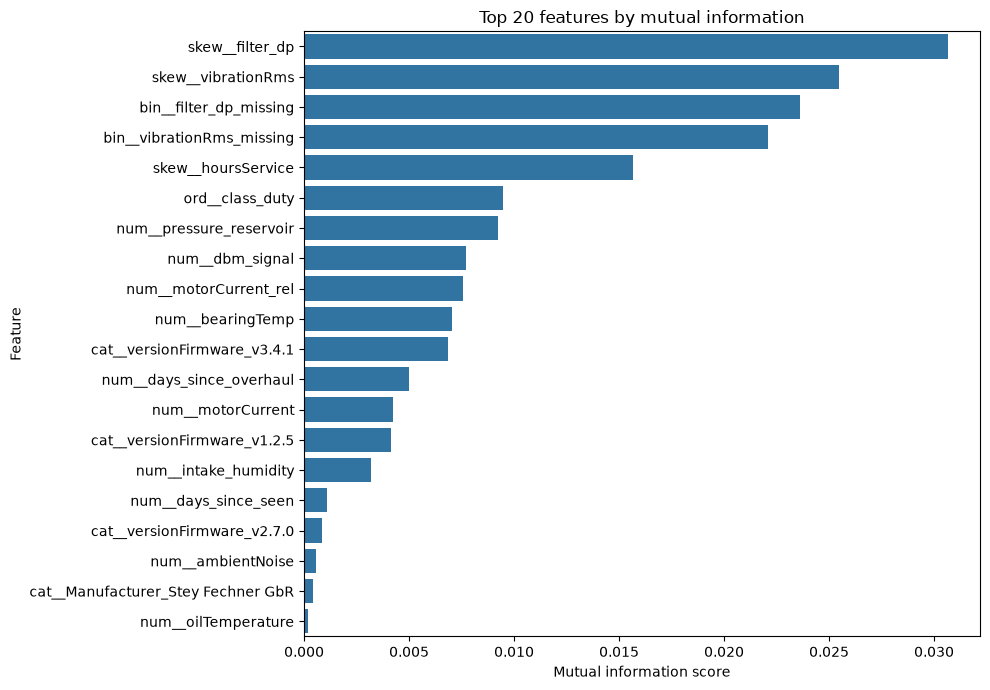

In [56]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=mi_ranking.head(20),
    x="mutual_information",
    y="feature"
)

plt.title("Top 20 features by mutual information")
plt.xlabel("Mutual information score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [57]:
print("Failure rate by filter_dp missingness:")

display(
    pd.crosstab(
        X_train["filter_dp_missing"],
        y_train,
        normalize="index"
    )
)

Failure rate by filter_dp missingness:


failure,0,1
filter_dp_missing,,
0,0.897477,0.102523
1,0.455635,0.544365


In [58]:
print("Failure rate by vibrationRms missingness:")

display(
    pd.crosstab(
        X_train["vibrationRms_missing"],
        y_train,
        normalize="index"
    )
)

Failure rate by vibrationRms missingness:


failure,0,1
vibrationRms_missing,,
0,0.896216,0.103784
1,0.452196,0.547804


### The failure rate was approximately 10% when "filter_dp" and "vibrationRms" were available, but approximately 54–55% when the corresponding measurementwas missing. Missingness is therefore strongly associated with the target, which explains the high mutual-information ranking of both missingness indicators

## Random Forest

,feature,random_forest_importance
0,skew__filter_dp,0.064563
1,skew__hoursService,0.064080
2,num__motorCurrent_rel,0.062430
3,num__motorCurrent,0.048701
4,num__bearingTemp,0.047182
5,skew__vibrationRms,0.046119
6,bin__vibrationRms_missing,0.043821
7,bin__filter_dp_missing,0.043308
8,num__pressure_reservoir,0.040554
9,num__pressureOil,0.040142


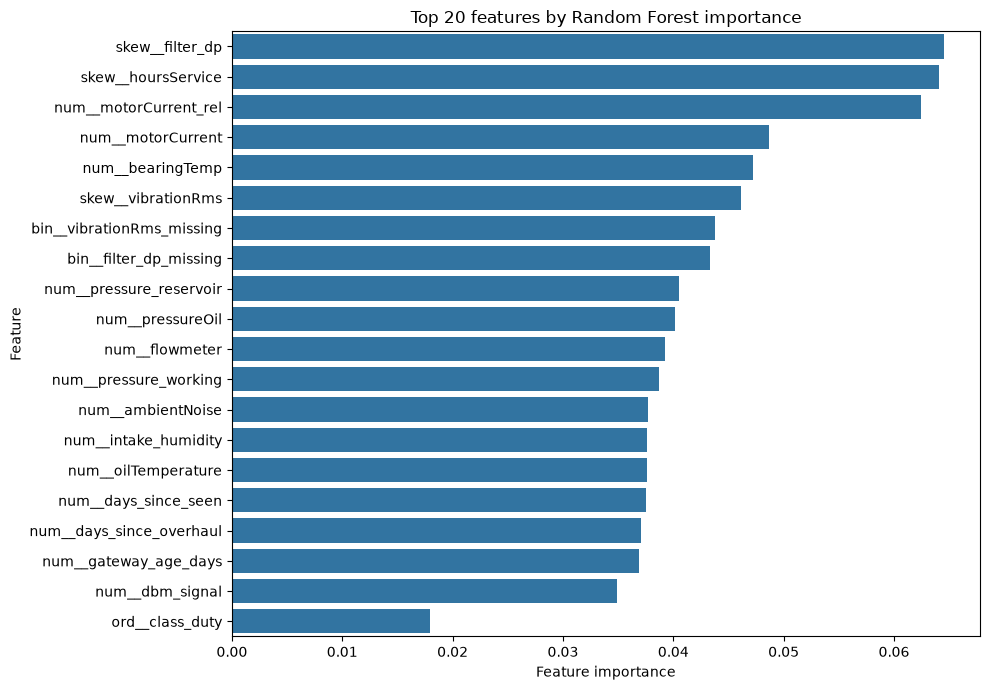

In [59]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_final,
    y_train
)

rf_ranking = pd.DataFrame({
    "feature": X_train_final.columns,
    "random_forest_importance":
        rf_model.feature_importances_
})

rf_ranking = (
    rf_ranking
    .sort_values(
        "random_forest_importance",
        ascending=False
    )
    .reset_index(drop=True)
)

display(rf_ranking.head(20))

plt.figure(figsize=(10, 7))

sns.barplot(
    data=rf_ranking.head(20),
    x="random_forest_importance",
    y="feature"
)

plt.title("Top 20 features by Random Forest importance")
plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Random Forest identified "filter_dp", "hoursService","motorCurrent_rel" , "motorCurrent", "bearingTemp", and "vibrationRms" as the most important features. Both missingness indicators also ranked highly.The results broadly agree with mutual information, especially for"filter_dp" , "vibrationRms", "hoursService", "bearingTemp", and the missingnessindicators. Random Forest additionally assigned relatively high importanceto "motorCurrent" and "pressureOil". Differences between the rankings areexpected because mutual information evaluates dependency with the targetindividually, whereas Random Forest evaluates features while constructingthe classification model.

## L1 (logistic regression)

Selected features: 67 out of 74


,feature,coefficient,absolute_coefficient,selected,l1_rank
0,bin__vibrationRms_missing,2.539945,2.539945,True,1
1,bin__filter_dp_missing,2.525529,2.525529,True,2
2,num__motorCurrent_rel,0.598122,0.598122,True,3
3,cat__Manufacturer_Stey Fechner GbR,0.471200,0.471200,True,4
4,num__pressure_reservoir,-0.441925,0.441925,True,5
5,skew__hoursService,0.429267,0.429267,True,6
6,ord__class_duty,-0.419868,0.419868,True,7
7,cat__Manufacturer_Tran-Lewis,0.398298,0.398298,True,8
8,cat__Manufacturer_Fleming Group,0.389894,0.389894,True,9
9,num__bearingTemp,0.379103,0.379103,True,10


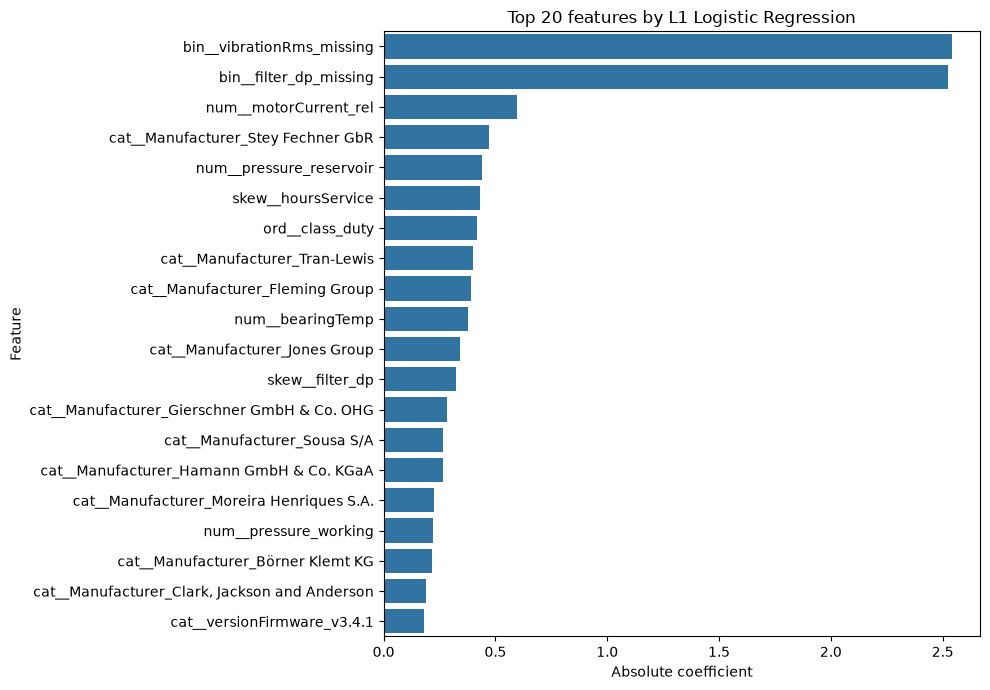

In [60]:
l1_model = LogisticRegression(
    l1_ratio= 1.0,
    solver="liblinear",
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

l1_model.fit(X_train_final, y_train)

l1_ranking = pd.DataFrame({
    "feature": X_train_final.columns,
    "coefficient": l1_model.coef_[0]
})

l1_ranking["absolute_coefficient"] = (
    l1_ranking["coefficient"].abs()
)

l1_ranking["selected"] = (
    l1_ranking["absolute_coefficient"] > 1e-8
)

l1_ranking = l1_ranking.sort_values(
    "absolute_coefficient",
    ascending=False
).reset_index(drop=True)

l1_ranking["l1_rank"] = (
    l1_ranking["absolute_coefficient"]
    .rank(ascending=False, method="min")
    .astype(int)
)

print(
    "Selected features:",
    l1_ranking["selected"].sum(),
    "out of",
    len(l1_ranking)
)

display(l1_ranking.head(20))

top_l1 = l1_ranking.head(20)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_l1,
    x="absolute_coefficient",
    y="feature"
)

plt.title("Top 20 features by L1 Logistic Regression")
plt.xlabel("Absolute coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### L1-regularized Logistic Regression identified the missingness indicators for vibrationRms and filter_dp as the most informative features. This agrees with the Mutual Information and Random Forest results. Other important attributes include relative motor current, reservoir pressure, service hours, duty class and bearing temperature. Several encoded manufacturer categories also received relatively large coefficients. With the selected regularization strength, 67 out of 74 features had non-zero coefficients.

In [61]:
for C in [0.001, 0.01, 0.1, 1, 10]:
    model = LogisticRegression(
        l1_ratio= 1.0,
        solver="liblinear",
        C=C,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )

    model.fit(X_train_final, y_train)

    selected = np.sum(np.abs(model.coef_[0]) > 1e-8)

    print(f"C={C}: selected {selected}/{X_train_final.shape[1]} features")

C=0.001: selected 1/74 features
C=0.01: selected 12/74 features
C=0.1: selected 33/74 features
C=1: selected 67/74 features
C=10: selected 69/74 features


### here I represented how C influence the number of selected featueres

In [62]:

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for C in [0.001, 0.01, 0.1, 1, 10]:
    model = LogisticRegression(
        l1_ratio=1.0,
        solver="liblinear",
        C=C,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )

    scores = cross_validate(
        model,
        X_train_final,
        y_train,
        cv=cv,
        scoring=["roc_auc", "f1", "precision", "recall"],
        n_jobs=-1
    )

    model.fit(X_train_final, y_train)

    selected = np.sum(
        np.abs(model.coef_[0]) > 1e-8
    )

    results.append({
        "C": C,
        "selected_features": selected,
        "roc_auc": scores["test_roc_auc"].mean(),
        "f1": scores["test_f1"].mean(),
        "precision": scores["test_precision"].mean(),
        "recall": scores["test_recall"].mean()
    })

l1_comparison = pd.DataFrame(results)
display(l1_comparison)

,C,selected_features,roc_auc,f1,precision,recall
0,0.001,1,0.500000,0.000000,0.000000,0.000000
1,0.010,12,0.800044,0.413005,0.295728,0.685932
2,0.100,33,0.801405,0.419668,0.303184,0.682592
3,1.000,67,0.796174,0.417378,0.301464,0.679238
4,10.000,69,0.795290,0.415744,0.300028,0.677561


### Different values of parameter C were compared using 5-fold cross-validation. The value C=0.1 achieved the highest average ROC-AUC and F1-score while selecting only 33 of 74 features. Therefore, it provided the best compromise between predictive performance and model simplicity and was selected for the final L1 Logistic Regression model.

## Final L1 ranking

In [63]:
l1_model = LogisticRegression(
    l1_ratio=1.0,
    solver="liblinear",
    C=0.1,
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

l1_model.fit(X_train_final, y_train)

l1_ranking = pd.DataFrame({
    "feature": X_train_final.columns,
    "coefficient": l1_model.coef_[0]
})

l1_ranking["absolute_coefficient"] = (
    l1_ranking["coefficient"].abs()
)

l1_ranking["selected"] = (
    l1_ranking["absolute_coefficient"] > 1e-8
)

l1_ranking = l1_ranking.sort_values(
    "absolute_coefficient",
    ascending=False
).reset_index(drop=True)

l1_ranking["l1_rank"] = (
    l1_ranking["absolute_coefficient"]
    .rank(ascending=False, method="min")
    .astype(int)
)

print("Selected features:", l1_ranking["selected"].sum())
display(l1_ranking.head(20))

Selected features: 33


,feature,coefficient,absolute_coefficient,selected,l1_rank
0,bin__filter_dp_missing,2.384384,2.384384,True,1
1,bin__vibrationRms_missing,2.382516,2.382516,True,2
2,num__motorCurrent_rel,0.577030,0.577030,True,3
3,skew__hoursService,0.418084,0.418084,True,4
4,ord__class_duty,-0.400968,0.400968,True,5
5,num__bearingTemp,0.359586,0.359586,True,6
6,skew__filter_dp,0.313626,0.313626,True,7
7,cat__Manufacturer_Stey Fechner GbR,0.312024,0.312024,True,8
8,num__pressure_reservoir,-0.225995,0.225995,True,9
9,cat__Manufacturer_Tran-Lewis,0.189978,0.189978,True,10


### L1 Logistic Regression with C=0.1 selected 33 of 74 features. The most important were the missing-value indicators for filter_dp and vibrationRms. The results generally agree with the other feature-selection methods.

In [64]:
mi_ranking["mi_rank"] = (
    mi_ranking["mutual_information"]
    .rank(ascending=False, method="min")
    .astype(int)
)

rf_ranking["rf_rank"] = (
    rf_ranking["random_forest_importance"]
    .rank(ascending=False, method="min")
    .astype(int)
)

In [65]:
combined_ranking = (
    mi_ranking[
        ["feature", "mutual_information", "mi_rank"]
    ]
    .merge(
        rf_ranking[
            ["feature", "random_forest_importance", "rf_rank"]
        ],
        on="feature"
    )
    .merge(
        l1_ranking[
            ["feature", "absolute_coefficient", "l1_rank"]
        ],
        on="feature"
    )
)

combined_ranking["average_rank"] = combined_ranking[
    ["mi_rank", "rf_rank", "l1_rank"]
].mean(axis=1)

combined_ranking = combined_ranking.sort_values(
    "average_rank"
).reset_index(drop=True)

combined_ranking["final_rank"] = (
    combined_ranking.index + 1
)

display(combined_ranking.head(20))

,feature,mutual_information,mi_rank,random_forest_importance,rf_rank,absolute_coefficient,l1_rank,average_rank,final_rank
0,skew__filter_dp,0.030655,1,0.064563,1,0.313626,7,3.000000,1
1,skew__hoursService,0.015663,5,0.064080,2,0.418084,4,3.666667,2
2,bin__filter_dp_missing,0.023594,3,0.043308,8,2.384384,1,4.000000,3
3,bin__vibrationRms_missing,0.022093,4,0.043821,7,2.382516,2,4.333333,4
4,num__motorCurrent_rel,0.007571,9,0.062430,3,0.577030,3,5.000000,5
5,num__bearingTemp,0.007045,10,0.047182,5,0.359586,6,7.000000,6
6,skew__vibrationRms,0.025485,2,0.046119,6,0.116052,15,7.666667,7
7,num__pressure_reservoir,0.009249,7,0.040554,9,0.225995,9,8.333333,8
8,ord__class_duty,0.009480,6,0.017963,20,0.400968,5,10.333333,9
9,cat__versionFirmware_v3.4.1,0.006854,11,0.010182,21,0.178762,11,14.333333,10


### all feature selection techniques results combined.

### The combined ranking shows that filter_dp, hoursService, missing-value indicators, relative motor current and bearing temperature are consistently informative. Although the methods produce slightly different rankings, they generally agree on the most important attributes.

In [66]:

feature_counts = [10, 20, 30, len(combined_ranking)]
selection_results = []

for count in feature_counts:
    selected_features = combined_ranking.head(count)["feature"].tolist()

    model = LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )

    scores = cross_validate(
        model,
        X_train_final[selected_features],
        y_train,
        cv=cv,
        scoring=["roc_auc", "f1", "precision", "recall"],
        n_jobs=-1
    )

    selection_results.append({
        "features": count,
        "roc_auc": scores["test_roc_auc"].mean(),
        "f1": scores["test_f1"].mean(),
        "precision": scores["test_precision"].mean(),
        "recall": scores["test_recall"].mean()
    })

selection_comparison = pd.DataFrame(selection_results)
display(selection_comparison)

,features,roc_auc,f1,precision,recall
0,10,0.804273,0.422777,0.305596,0.686769
1,20,0.803622,0.420078,0.303473,0.683408
2,30,0.803096,0.421267,0.304006,0.686783
3,74,0.795530,0.412936,0.297951,0.673366


### The top 10 features are the best choice. They produce the highest ROC-AUC, F1 and precision, while recall is almost identical to the 30-feature version.

In [67]:
selected_features = (
    combined_ranking
    .head(10)["feature"]
    .tolist()
)

print("Final selected features:")
for feature in selected_features:
    print(feature)

class FeatureSelector(BaseEstimator, TransformerMixin):
    def __init__(self, features):
        self.features = features

    def fit(self, X, y=None):
        missing_features = set(self.features) - set(X.columns)

        if missing_features:
            raise ValueError(
                f"Missing features: {missing_features}"
            )

       
        self.features_ = np.asarray(
            self.features,
            dtype=object
        )

        self.n_features_in_ = X.shape[1]

        return self

    def transform(self, X):
        return X.loc[:, self.features_].copy()

    def get_feature_names_out(self, input_features=None):
        return self.features_

Final selected features:
skew__filter_dp
skew__hoursService
bin__filter_dp_missing
bin__vibrationRms_missing
num__motorCurrent_rel
num__bearingTemp
skew__vibrationRms
num__pressure_reservoir
ord__class_duty
cat__versionFirmware_v3.4.1


### The top 10 features achieved the best cross-validation results and were selected for further modelling. To ensure reproducibility, this selection will be included as the final step of the preprocessing pipeline and automatically applied to both training and test data.

In [68]:
final_pipeline = Pipeline([
    ("preprocessing", clone(selected_preprocessor)),
    ("selection", FeatureSelector(selected_features))
])

In [69]:
X_train_final_selected = final_pipeline.fit_transform(
    X_train,
    y_train
)

X_test_final_selected = final_pipeline.transform(
    X_test
)

print("Train shape:", X_train_final_selected.shape)
print("Test shape:", X_test_final_selected.shape)

print(
    "Same columns:",
    X_train_final_selected.columns.equals(
        X_test_final_selected.columns
    )
)

print(
    "Missing values in train:",
    X_train_final_selected.isna().sum().sum()
)

print(
    "Missing values in test:",
    X_test_final_selected.isna().sum().sum()
)

print(
    "All train columns numerical:",
    all(
        pd.api.types.is_numeric_dtype(dtype)
        for dtype in X_train_final_selected.dtypes
    )
)

display(X_train_final_selected.head())

Train shape: (9849, 10)
Test shape: (2462, 10)
Same columns: True
Missing values in train: 0
Missing values in test: 0
All train columns numerical: True


,skew__filter_dp,skew__hoursService,bin__filter_dp_missing,bin__vibrationRms_missing,num__motorCurrent_rel,num__bearingTemp,skew__vibrationRms,num__pressure_reservoir,ord__class_duty,cat__versionFirmware_v3.4.1
0,0.707130,-1.024598,0.0,0.0,-0.944085,0.003401,1.264751,-1.671385,2.0,1.0
1,0.185510,-0.016017,0.0,0.0,0.607284,0.876365,-0.775939,-0.218873,1.0,1.0
3,0.236479,0.047731,0.0,0.0,-0.877301,0.266589,-0.493417,1.749701,2.0,0.0
4,-0.573928,-0.440308,0.0,0.0,-1.267885,-0.492943,0.870294,-1.018542,2.0,0.0
5,0.673932,-0.667796,0.0,0.0,-0.211191,0.078773,0.413386,0.402532,1.0,1.0


### The final pipeline was fitted only on the training data and then applied to the test data. Both datasets contain the same 10 numerical features and no missing values, confirming that the preprocessing and feature selection are reproducible.

In [70]:
output_directory = Path("processed_data")
output_directory.mkdir(exist_ok=True)

train_output = X_train_final_selected.copy()
test_output = X_test_final_selected.copy()

train_output["failure"] = y_train.to_numpy()
test_output["failure"] = y_test.to_numpy()

train_output.to_csv(
    output_directory / "train_preprocessed.csv",
    index=False
)

test_output.to_csv(
    output_directory / "test_preprocessed.csv",
    index=False
)

print("Train shape:", train_output.shape)
print("Test shape:", test_output.shape)



Train shape: (9849, 11)
Test shape: (2462, 11)


### The final training and test datasets were saved as CSV files. Each dataset contains 10 selected numerical features and the target variable `failure`, with one observation represented by one row.